# 1 · Data inspection — reading and quality verification

Each check logs `PASS / WARN / FAIL` into the final summary table.
Section 8 covers **OLS screening** (via statsmodels) for calendar hypotheses. This serves as exploratory analysis rather than the final model: all findings here are re-evaluated within the Bayesian MMM (`3_modeling`).

In [1]:
import os, sys
from pathlib import Path
try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# --- Colab ---
#PROJECT_DIR = "/content/drive/MyDrive/digis"
#  local ---
PROJECT_DIR = "."

if IN_COLAB:
    drive.mount("/content/drive")
root = Path(PROJECT_DIR).resolve()
if not (root / "notebooks").exists() and (root.parent / "notebooks").exists():
    root = root.parent
assert (root / "notebooks" / "common.py").exists(), (
    f"Not found {root}/notebooks/common.py.")
os.chdir(root / "notebooks"); sys.path.insert(0, str(root / "notebooks"))
print("root :", root, "| Colab:", IN_COLAB)

root : /Users/anastasiiazabolotna/Documents/me/digis/digis | Colab: False


In [57]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import statsmodels.formula.api as smf, statsmodels.api as sm
from scipy import stats
from statsmodels.stats.stattools import durbin_watson
from statsmodels.stats.outliers_influence import variance_inflation_factor as vif
import importlib, common
importlib.reload(common)
from common import *
pd.set_option("display.width",160); pd.set_option("display.max_columns",30)

RESULTS=[]
def log(name,status,detail=""):
    RESULTS.append((name,status,detail)); print(f"[{status}] {name} — {detail}")

## Reading & Loading Data

In [58]:
df = load()
print(df.shape, df.date.min().date(), "→", df.date.max().date())
df.info()

(730, 15) 2024-10-01 → 2026-09-30
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 730 entries, 0 to 729
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   date         730 non-null    datetime64[ns]
 1   sales_inc    730 non-null    float64       
 2   sales_ex     730 non-null    float64       
 3   buyers       730 non-null    int64         
 4   orders       730 non-null    int64         
 5   new          730 non-null    int64         
 6   bing         730 non-null    float64       
 7   google       730 non-null    float64       
 8   meta         730 non-null    float64       
 9   pinterest    730 non-null    float64       
 10  spend_total  730 non-null    float64       
 11  promo        730 non-null    float64       
 12  bf           730 non-null    int64         
 13  cm           730 non-null    int64         
 14  window       730 non-null    int64         
dtypes: datetime64[ns](1), f

## Completeness

In [59]:
gaps = pd.date_range(df.date.min(), df.date.max()).difference(df.date)
log("Missing dates", "PASS" if len(gaps) == 0 else "FAIL", f"{len(gaps)}")
log("Duplicate dates", "PASS" if df.date.duplicated().sum() == 0 else "FAIL", f"{df.date.duplicated().sum()}")
log("NaN values", "PASS" if df.isna().sum().sum() == 0 else "FAIL", f"{df.isna().sum().sum()}")
log("Negative values", "PASS" if (df.drop(columns="date") < 0).sum().sum() == 0 else "FAIL", "")
log("Zero channel spend", "PASS" if (df[CH] == 0).sum().sum() == 0 else "WARN", str((df[CH] == 0).sum().to_dict()))

[PASS] Missing dates — 0
[PASS] Duplicate dates — 0
[PASS] NaN values — 0
[PASS] Negative values — 
[PASS] Zero channel spend — {'bing': 0, 'google': 0, 'meta': 0, 'pinterest': 0}


## Internal Consistency

In [60]:
d=(df[CH].sum(axis=1)-df.spend_total).abs().max()
log("Σ channels = Total spend","PASS" if d<0.01 else "FAIL",f"max discrepancy £{d:.1e}")
r=df.sales_inc/df.sales_ex
log("Sales inc / ex = 1.20","PASS" if r.between(1+TAX-1e-3,1+TAX+1e-3).all() else "FAIL",f"{r.min():.5f}–{r.max():.5f}")
log("New ≤ Purchasing customers","PASS" if (df.new<=df.buyers).all() else "FAIL","")
log("Orders ≥ Purchasing customers","PASS" if (df.orders>=df.buyers).all() else "FAIL","")
log("Binary flags","PASS" if df[["bf","cm","window"]].isin([0,1]).all().all() else "FAIL","")
log("BF and CM ⊂ window","PASS" if ((df.bf+df.cm)<=df.window).all() else "FAIL",f"window: {int(df.window.sum())} days")
log("Discount in [0,1]","PASS" if df.promo.between(0,1).all() else "FAIL",f"max {df.promo.max()}")

[PASS] Σ channels = Total spend — max discrepancy £3.6e-12
[PASS] Sales inc / ex = 1.20 — 1.20000–1.20000
[PASS] New ≤ Purchasing customers — 
[PASS] Orders ≥ Purchasing customers — 
[PASS] Binary flags — 
[PASS] BF and CM ⊂ window — window: 16 days
[PASS] Discount in [0,1] — max 0.25


## Column Redundancy Audit

In [61]:
num = df.drop(columns="date")
c = num.corr().abs()
pairs = [(a,b,c.loc[a,b]) for i,a in enumerate(c) for b in c.columns[i+1:] if c.loc[a,b]>0.99]
print(pd.DataFrame(pairs,columns=["col_a","col_b","|r|"]).sort_values("|r|",ascending=False).round(4).to_string(index=False))
log("Duplicate / near-duplicate columns","WARN",f"{len(pairs)} pairs with |r|>0.99: sales_inc≡sales_ex (×1.2), spend_total=Σchannels, buyers≈orders≈new (consequences of advertising, not drivers)")

    col_a    col_b    |r|
sales_inc sales_ex 1.0000
   buyers   orders 0.9999
   buyers      new 0.9938
   orders      new 0.9937
 sales_ex   orders 0.9905
sales_inc   orders 0.9905
 sales_ex   buyers 0.9903
sales_inc   buyers 0.9903
[WARN] Duplicate / near-duplicate columns — 8 pairs with |r|>0.99: sales_inc≡sales_ex (×1.2), spend_total=Σchannels, buyers≈orders≈new (consequences of advertising, not drivers)


## Units & Scale of Magnitudes

In [62]:
print(df[CH+["spend_total","sales_ex","new"]].describe().loc[["min","50%","mean","max"]].round(0))
avg_cac=df.spend_total.sum()/df.new.sum()
log("Overall average CAC","PASS",f"£{avg_cac:.1f} — this is NOT comparable to £{TARGET_CAC} (the latter is marginal CAC)")

        bing   google     meta  pinterest  spend_total  sales_ex     new
min     98.0    848.0    518.0       57.0       1994.0   18453.0   127.0
50%    310.0   2038.0   2559.0      459.0       5494.0   50652.0   385.0
mean   332.0   2297.0   2876.0      500.0       6004.0   54311.0   429.0
max   1070.0  13488.0  19251.0     3029.0      36653.0  208474.0  2290.0
[PASS] Overall average CAC — £14.0 — this is NOT comparable to £40 (the latter is marginal CAC)


## Anomalies & Outliers

Days with |robust z|>4 for new: 24
      date  new  promo  bf  cm  window
2024-11-25 1002   0.20   0   0       1
2024-11-27  951   0.20   0   0       1
2024-11-28  897   0.20   0   0       1
2024-11-29 1870   0.25   1   0       1
2024-11-30 1053   0.20   0   0       1
2024-12-01 1229   0.20   0   0       1
2024-12-02 1748   0.25   0   1       1
2024-12-24  130   0.00   0   0       0
2024-12-25  127   0.00   0   0       0
2025-11-24 1316   0.20   0   0       1
2025-11-25 1320   0.20   0   0       1
2025-11-26 1298   0.20   0   0       1
2025-11-27 1316   0.20   0   0       1
2025-11-28 2290   0.25   1   0       1
2025-11-29 1372   0.20   0   0       1
2025-11-30 1470   0.20   0   0       1
2025-12-01 2209   0.25   0   1       1
2025-12-24  177   0.00   0   0       0
2025-12-25  190   0.00   0   0       0
2025-12-28  782   0.15   0   0       0
2025-12-30  674   0.15   0   0       0
2025-12-31  674   0.15   0   0       0
2026-06-19  590   0.10   0   0       0
2026-06-21  664   0.10   0   

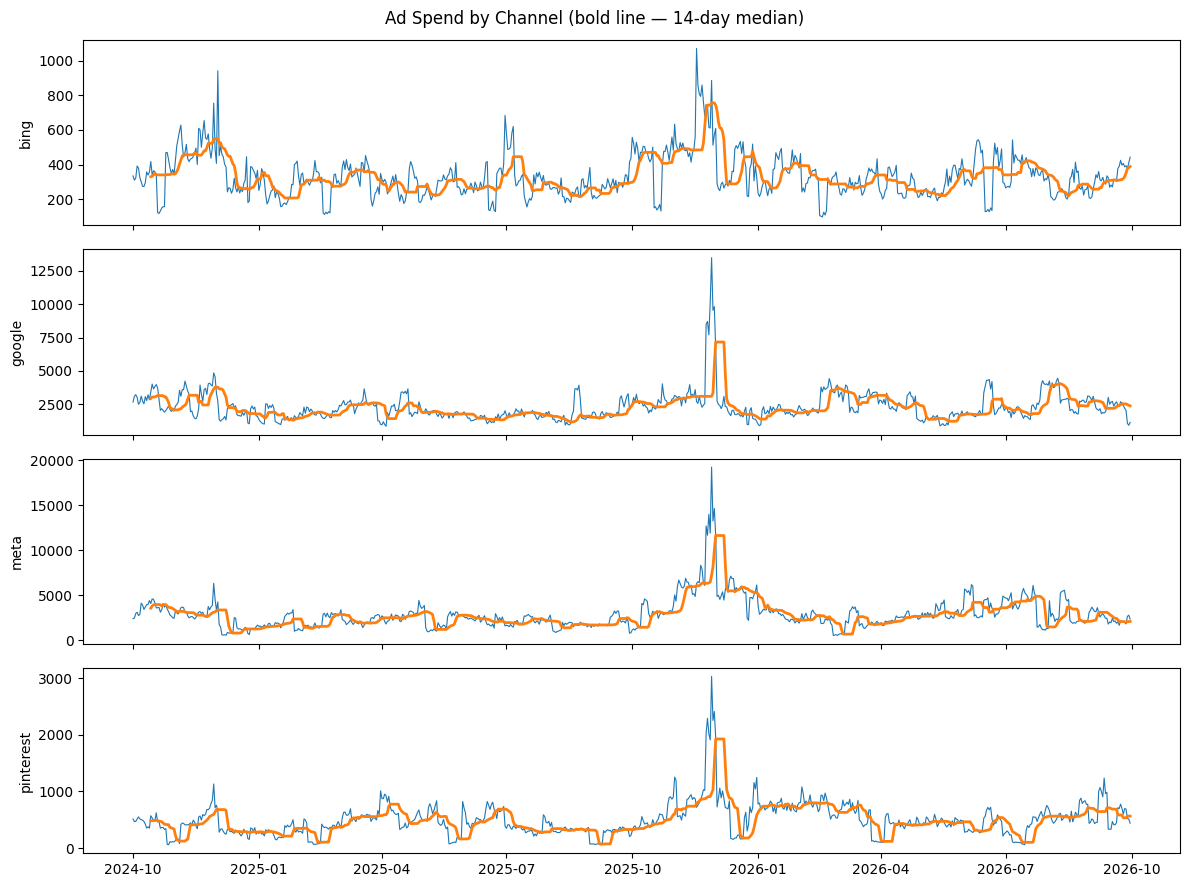

[WARN] Step changes in spend (Bing, Pinterest) — sharp shifts of level ×2–×6: useful variation, but verify with the client that these are genuine budgets and not tracking anomalies
[WARN] Outliers in target (new) — almost all are legitimate retail events (BF, Christmas). Do not drop them; model them via indicator flags


In [63]:
def robust_z(s,win=57):
    med=s.rolling(win,center=True,min_periods=15).median()
    mad=(s-med).abs().rolling(win,center=True,min_periods=15).median()*1.4826
    return (s-med)/mad
z=robust_z(df.new); out=df[z.abs()>4]
print("Days with |robust z|>4 for new:",len(out)); print(out[["date","new","promo","bf","cm","window"]].to_string(index=False))

fig,ax=plt.subplots(4,1,figsize=(12,9),sharex=True)
for a,ch in zip(ax,CH):
    a.plot(df.date,df[ch],lw=.8); a.plot(df.date,df[ch].rolling(14).median(),lw=2); a.set_ylabel(ch)
plt.suptitle("Ad Spend by Channel (bold line — 14-day median)"); plt.tight_layout(); plt.show()
log("Step changes in spend (Bing, Pinterest)","WARN","sharp shifts of level ×2–×6: useful variation, but verify with the client that these are genuine budgets and not tracking anomalies")
log("Outliers in target (new)","WARN","almost all are legitimate retail events (BF, Christmas). Do not drop them; model them via indicator flags")

## Events: Black Friday / Cyber Monday / Christmas

In [64]:
def black_friday(y):
    nov = pd.date_range(f"{y}-11-01", f"{y}-11-30")
    return nov[nov.weekday == 3][3] + pd.Timedelta(days=1)
for y in sorted(df.date.dt.year.unique()):
    f = df.loc[(df.bf == 1) & (df.date.dt.year == y), "date"]
    g = df.loc[(df.cm == 1) & (df.date.dt.year == y), "date"]
    if len(f):
        ok = f.iloc[0] == black_friday(y) and g.iloc[0] == black_friday(y) + pd.Timedelta(days=3)
        log(f"BF/CM dates {y}", "PASS" if ok else "FAIL", f"{f.iloc[0].date()} / {g.iloc[0].date()}")
xm = (df.date.dt.month == 12) & (df.date.dt.day.isin([24, 25])); eff = []
for y in df.date.dt.year.unique():
    s_ = df[xm & (df.date.dt.year == y)]; n_ = df[(df.date.dt.year == y) & (df.date.dt.month == 12) & (df.date.dt.day.between(15, 22))]
    if len(s_): eff.append((s_.new.mean() / n_.new.mean() - 1, s_.spend_total.mean() / n_.spend_total.mean() - 1))
cd, sd = np.mean([e[0] for e in eff]), np.mean([e[1] for e in eff])
log("Christmas 24-25.12", "WARN", f"customers {cd:+.0%}, spend {sd:+.0%}. Customers drop sharper than spend → flag needed, otherwise model will misinterpret this as a drop in ad efficiency")

[PASS] BF/CM dates 2024 — 2024-11-29 / 2024-12-02
[PASS] BF/CM dates 2025 — 2025-11-28 / 2025-12-01
[WARN] Christmas 24-25.12 — customers -72%, spend -48%. Customers drop sharper than spend → flag needed, otherwise model will misinterpret this as a drop in ad efficiency


## Target Distribution & Normality
Normality is required for the **model residuals**, not the raw data. Here: determining which target scale is more convenient.

new:      skew=4.73  kurt=32.9
log(new): skew=1.57  kurt=5.7


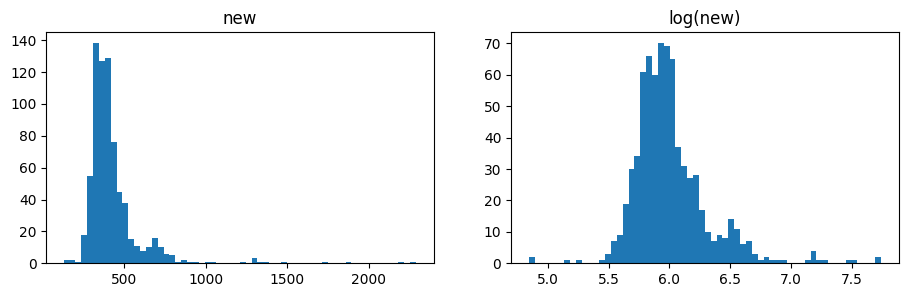

[PASS] Target scale — raw new is heavily skewed (BF); log(new) is much closer to normal → Normal on log-scale or NegBinomial


In [65]:
print(f"new:      skew={stats.skew(df.new):.2f}  kurt={stats.kurtosis(df.new):.1f}")
print(f"log(new): skew={stats.skew(np.log(df.new)):.2f}  kurt={stats.kurtosis(np.log(df.new)):.1f}")
fig,ax=plt.subplots(1,2,figsize=(11,3)); ax[0].hist(df.new,60); ax[0].set_title("new"); ax[1].hist(np.log(df.new),60); ax[1].set_title("log(new)"); plt.show()
log("Target scale","PASS","raw new is heavily skewed (BF); log(new) is much closer to normal → Normal on log-scale or NegBinomial")

### Why does the `new` distribution look like a sum of multiple distributions?
Because it is a **mixture of regimes**: standard days, discount days, the BF window, and BF..CM itself. The marginal target histogram does not need to be normal; we expect normality from the **residuals after accounting for regimes** (see Section 10d). Below, we break down the data by regime and test for a Gaussian Mixture (GMM).

                              days  median   min   max  discount_med
regime                                                              
BF..CM (4 days)                  8  1609.0  1053  2290          0.22
discount outside BF             60   488.0   280   863          0.15
no discount                    654   379.0   127   823          0.00
remaining BF window (4 days)     8  1150.0   875  1320          0.20


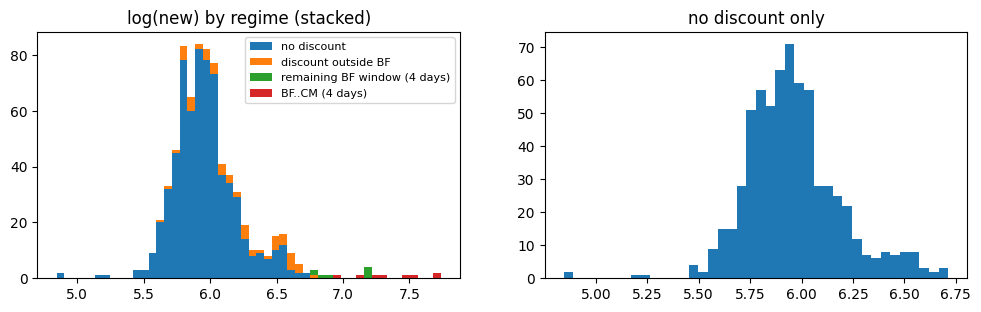

Gaussian Mixture BIC for log(new): {1: np.float64(361.7), 2: np.float64(127.3), 3: np.float64(144.8)} → best k = 2
Even 'no discount' has 2 components: [439. 366.] (trend/seasonality: Oct-Dec 2024 higher)
[PASS] Target distribution = regime mixture — mixture of >=2 components expected (discounts, BF, seasonality); explained by model features rather than violating assumptions; normality verified on residuals (10d)


In [66]:
from sklearn.mixture import GaussianMixture
R=df.copy(); R["peak"]=bf_cm_peak(R)
R["regime"]=np.select([R.peak==1,(R.window==1),R.promo>0],["BF..CM (4 days)","remaining BF window (4 days)","discount outside BF"],"no discount")
print(R.groupby("regime").agg(days=("new","size"),median=("new","median"),min=("new","min"),max=("new","max"),discount_med=("promo","median")).round(2))
order=["no discount","discount outside BF","remaining BF window (4 days)","BF..CM (4 days)"]
fig,ax=plt.subplots(1,2,figsize=(12,3.2))
ax[0].hist([np.log(R.loc[R.regime==o,"new"]) for o in order],bins=50,stacked=True,label=order); ax[0].legend(fontsize=8); ax[0].set_title("log(new) by regime (stacked)")
ax[1].hist(np.log(R.loc[R.regime=="no discount","new"]),bins=40); ax[1].set_title("no discount only"); plt.show()
X=np.log(R.new).values.reshape(-1,1); bic={k:GaussianMixture(k,n_init=5,random_state=0).fit(X).bic(X) for k in (1,2,3)}
print("Gaussian Mixture BIC for log(new):",{k:round(v,1) for k,v in bic.items()},"→ best k =",min(bic,key=bic.get))
Xb=np.log(R.loc[R.regime=="no discount","new"]).values.reshape(-1,1); g=GaussianMixture(2,n_init=5,random_state=0).fit(Xb)
print("Even 'no discount' has 2 components:",np.exp(g.means_.ravel()).round(0),"(trend/seasonality: Oct-Dec 2024 higher)")
log("Target distribution = regime mixture","PASS","mixture of >=2 components expected (discounts, BF, seasonality); explained by model features rather than violating assumptions; normality verified on residuals (10d)")

## Channel Collinearity

In [67]:
print(df[CH].corr().round(2))
X=sm.add_constant(np.log(df[CH])); v={c:round(vif(X.values,i),1) for i,c in enumerate(X.columns) if c!="const"}; print("VIF (log spend):",v)
log("Channel collinearity","PASS" if max(v.values())<5 else "WARN",f"VIF {v} — individual channel effects are identifiable")
print("promo vs BF-window corr:",round(df.promo.corr(df.window),2))
log("promo ↔ BF","WARN",f"corr(promo, window)={df.promo.corr(df.window):.2f}: discount effect and BF effect are nearly indistinguishable")

           bing  google  meta  pinterest
bing       1.00    0.29  0.40       0.26
google     0.29    1.00  0.52       0.57
meta       0.40    0.52  1.00       0.54
pinterest  0.26    0.57  0.54       1.00
VIF (log spend): {'bing': np.float64(1.1), 'google': np.float64(1.2), 'meta': np.float64(1.1), 'pinterest': np.float64(1.1)}
[PASS] Channel collinearity — VIF {'bing': np.float64(1.1), 'google': np.float64(1.2), 'meta': np.float64(1.1), 'pinterest': np.float64(1.1)} — individual channel effects are identifiable
promo vs BF-window corr: 0.64
[WARN] promo ↔ BF — corr(promo, window)=0.64: discount effect and BF effect are nearly indistinguishable


## Calendar Effects  (OLS on log(new)) — EXPLORATORY
No media variables: calendar, discount, and trend only. Purpose: hypotheses for the model, not conclusions.
(For `bf_cm_peak` in this section, the function from `common.py` is used.)

In [68]:
S=df.copy(); S["y"]=np.log(S.new); S["dow"]=S.date.dt.dayofweek; S["t"]=np.arange(len(S)); S["doy"]=S.date.dt.dayofyear
S["bf_cm_peak"]=bf_cm_peak(S); md_=S.date.dt.strftime("%m-%d"); S["xmas"]=md_.isin(["12-24","12-25"]).astype(int)
def frm(k, extra=""):
    F=fourier(k,S.doy) if k else pd.DataFrame(index=S.index)
    D=pd.concat([S,F],axis=1); return D,"y ~ C(dow)+bf_cm_peak+xmas+promo+t"+"".join("+"+c for c in F.columns)+extra

rows=[]
for k in range(0,7):
    D,f=frm(k); errs=[]
    for cut in ["2025-10-01","2026-01-01","2026-04-01","2026-07-01"]:
        tr=D[D.date<cut]; te=D[(D.date>=cut)&(D.date<pd.Timestamp(cut)+pd.Timedelta(days=90))&(D.xmas==0)&(D.bf_cm_peak==0)]
        errs.append(np.mean(np.abs(np.exp(smf.ols(f,tr).fit().predict(te))-te.new)/te.new))
    m=smf.ols(f,D).fit(); rows.append(dict(k=k,R2_in=m.rsquared,BIC=m.bic,MAPE_cv=np.mean(errs)))
res=pd.DataFrame(rows).round(4); print(res.to_string(index=False))
k_simple=int(res[res.MAPE_cv<=res.MAPE_cv.min()*1.05].k.min())


 k  R2_in       BIC  MAPE_cv
 0 0.4144   30.3499   0.2418
 1 0.5447 -140.2245   0.3070
 2 0.7688 -621.7117   0.1838
 3 0.8317 -840.2231   0.1348
 4 0.8460 -892.1445   0.1390
 5 0.8517 -906.1700   0.1566
 6 0.8569 -918.9053   0.1575


In [69]:
D,f=frm(k_simple)
wk=S[(S.xmas==0)&(S.bf_cm_peak==0)].groupby("dow").new.mean(); print((wk/wk.mean()).round(3).rename(index=dict(enumerate("Mon Tue Wed Thu Fri Sat Sun".split()))))
a=smf.ols(f.replace("C(dow)+",""),D).fit(); b=smf.ols(f,D).fit(); print("F-test day-of-week p =",b.compare_f_test(a)[1])
D["dom"]=D.date.dt.day; D["payday"]=D.dom.isin([25,26,27,28,29,30,31,1,2,3]).astype(int)
m1=smf.ols(f+"+payday",D).fit(); log("Monthly cycle (payday)","PASS" if m1.pvalues["payday"]>=.05 else "WARN",f"coef={m1.params['payday']:+.3f}, p={m1.pvalues['payday']:.2f} → do not add month harmonics")

dow
Mon    1.017
Tue    1.002
Wed    0.976
Thu    0.999
Fri    1.009
Sat    0.917
Sun    1.080
Name: new, dtype: float64
F-test day-of-week p = 1.7345572965926749e-18
[PASS] Monthly cycle (payday) — coef=+0.002, p=0.86 → do not add month harmonics


In [70]:
cands={"New Year 01.01":md_=="01-01","Halloween 31.10":md_=="10-31","Valentine 14.02":md_=="02-14","Boxing Day 26.12":md_=="12-26"}
rows=[]
for k_,v in cands.items():
    d=D.assign(h=v.astype(int)); m=smf.ols(f+"+h",d).fit(); rows.append((k_,int(d.h.sum()),round(m.params["h"],3),round(m.pvalues["h"],4)))
print(pd.DataFrame(rows,columns=["holiday","n","coef (log)","p"]).to_string(index=False))


         holiday  n  coef (log)      p
  New Year 01.01  2      -0.279 0.0024
 Halloween 31.10  2      -0.297 0.0011
 Valentine 14.02  2       0.020 0.8253
Boxing Day 26.12  2       0.057 0.5365


In [71]:
m = smf.ols(f, D).fit(); r = m.resid
print("Shapiro p:", round(stats.shapiro(r)[1], 3), "| skew/kurt:", round(stats.skew(r), 2), round(stats.kurtosis(r), 2))
print("Durbin–Watson:", round(durbin_watson(r), 2), "| ACF1:", round(r.autocorr(1), 2), "| Breusch–Pagan p:", round(sm.stats.diagnostic.het_breuschpagan(r, m.model.exog)[1], 4))
print(D.assign(resid=r).loc[r.abs().nlargest(8).index, ["date", "new", "promo", "resid"]].round(2).to_string(index=False))


Shapiro p: 0.609 | skew/kurt: -0.03 0.28
Durbin–Watson: 0.71 | ACF1: 0.64 | Breusch–Pagan p: 0.0
      date  new  promo  resid
2025-01-02  291   0.15  -0.45
2025-11-26 1298   0.20   0.40
2025-11-27 1316   0.20   0.39
2025-01-04  280   0.15  -0.39
2025-11-25 1320   0.20   0.39
2025-01-03  318   0.15  -0.38
2025-01-05  339   0.15  -0.35
2025-10-31  452   0.00  -0.35


Correlation Matrix:


,sales_inc,sales_ex,buyers,orders,new,bing,google,meta,pinterest,spend_total,promo,bf,cm,window
sales_inc,1.000000,1.000000,0.990315,0.990539,0.979705,0.522609,0.601418,0.721643,0.532597,0.779276,0.537578,0.402999,0.389821,0.702303
sales_ex,1.000000,1.000000,0.990315,0.990539,0.979705,0.522609,0.601418,0.721643,0.532597,0.779276,0.537578,0.402999,0.389821,0.702303
buyers,0.990315,0.990315,1.000000,0.999871,0.993799,0.528734,0.615011,0.720986,0.551986,0.786617,0.609113,0.445925,0.411254,0.749069
orders,0.990539,0.990539,0.999871,1.000000,0.993724,0.528921,0.614777,0.721080,0.552605,0.786658,0.609177,0.443136,0.412141,0.748104
new,0.979705,0.979705,0.993799,0.993724,1.000000,0.531296,0.633600,0.745886,0.570803,0.811995,0.615102,0.452337,0.424527,0.750765
bing,0.522609,0.522609,0.528734,0.528921,0.531296,1.000000,0.288097,0.402616,0.259964,0.443864,0.292050,0.206262,0.187279,0.345091
google,0.601418,0.601418,0.615011,0.614777,0.633600,0.288097,1.000000,0.521670,0.572246,0.804113,0.366281,0.329601,0.114148,0.592326
meta,0.721643,0.721643,0.720986,0.721080,0.745886,0.402616,0.521670,1.000000,0.542649,0.920470,0.392276,0.296798,0.151522,0.514085
pinterest,0.532597,0.532597,0.551986,0.552605,0.570803,0.259964,0.572246,0.542649,1.000000,0.691950,0.429266,0.281127,0.141827,0.512480
spend_total,0.779276,0.779276,0.786617,0.786658,0.811995,0.443864,0.804113,0.920470,0.691950,1.000000,0.454590,0.359468,0.165511,0.633342


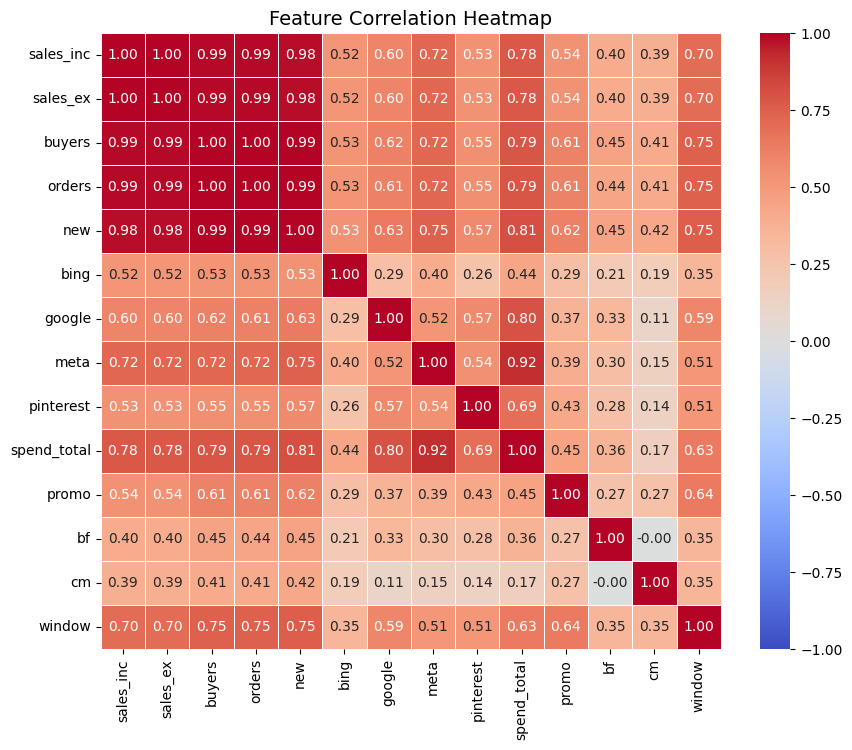

In [72]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate correlation matrix for numeric columns only
corr_matrix = df.select_dtypes(include=["number"]).corr()

# Print numeric correlation matrix to console
print("Correlation Matrix:")
display(corr_matrix)

# Plot heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_matrix,
    annot=True,  # display correlation values inside cells
    fmt=".2f",  # round values to two decimal places
    cmap="coolwarm",  # color palette
    vmin=-1,
    vmax=1,  # scale limits
    linewidths=0.5,
)
plt.title("Feature Correlation Heatmap", fontsize=14)
plt.show()